# Le pape François adapte-t-il ses discours aux pays qu'il visite ?

Projet de Python pour la data science, ENSAE, 2026. Auteurs : Arthur De Rouck, Adrien Vibert.

Entre 2013 et 2024, le pape François a fait 47 voyages hors d'Italie. Dans chaque pays, il prononce plusieurs discours devant des publics très différents : chefs d'État, évêques, jeunes, réfugiés, responsables d'autres religions. Le Vatican publie ces textes en anglais sur son site.

On cherche à savoir si ces discours changent selon le lieu et le public, ou s'ils reprennent partout les mêmes thèmes. Pour cela, on a collecté tous les discours prononcés pendant ces voyages, puis on les compare par continent, par type de public et dans le temps.

Le rapport suit quatre étapes : les données, la description du corpus, l'analyse, puis les limites.

> À rédiger. Quelques lignes sur l'intérêt de la question et sur ce que vous attendiez avant de regarder les données.

In [1]:
import sys
import textwrap
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RACINE / "outils"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

import analyse_corpus as ac
import graphiques as g

g.style()
pio.renderers.default = "plotly_mimetype+notebook_connected"
pd.set_option("display.max_colwidth", 70)

## 1. Les données

### D'où viennent les discours

Les textes viennent du site vatican.va. Deux scripts du dossier `acquisition` produisent les données.

1. `telecharger_discours.py` lit la liste des voyages hors d'Italie et leurs dates. Il parcourt ensuite les index mensuels des discours et garde ceux prononcés pendant un voyage. On obtient 415 textes.
2. `preparer_corpus.py` sépare l'en-tête de chaque texte (voyage, public, lieu, date) du discours lui-même. Il retire les conférences de presse dans l'avion, qui contiennent surtout les questions des journalistes, et deux discours prononcés au Vatican le matin d'un départ. Il reste 342 discours.

Les fichiers produits sont déposés sur le stockage du SSP Cloud. Le notebook les lit directement, sans relancer la collecte qui prend une dizaine de minutes.

In [2]:
df = ac.charger()
df[["date", "voyage", "pays", "public", "n_mots", "titre"]].head()

,date,voyage,pays,public,n_mots,titre
0,2013-07-22,Rio de Janeiro 2013,Brésil,Accueil et départ,990,Welcome Ceremony at the Garden of Guanabara Palace (Rio de Janeiro...
1,2013-07-24,Rio de Janeiro 2013,Brésil,Jeunes et éducation,111,Greeting to the young people from Italy at the conclusion of his v...
2,2013-07-24,Rio de Janeiro 2013,Brésil,"Pauvres, malades, migrants",999,Visit to the St. Francis of Assisi of the Providence of God Hospit...
3,2013-07-24,Rio de Janeiro 2013,Brésil,"Prière, mémoire, réconciliation",168,Impromptu address of Pope Francis from the balcony of the Basilica...
4,2013-07-25,Rio de Janeiro 2013,Brésil,Jeunes et éducation,2155,Welcoming Ceremony by the young people on the waterfront of Copaca...


### Variables construites

La table contient une ligne par discours. La fonction `ac.charger()` ajoute trois informations.

- Le pays et le continent. Le lieu écrit dans l'en-tête est comparé à une liste de pays et de villes. S'il manque, on prend le pays du voyage quand il n'y en a qu'un, sinon celui des autres discours du même jour.
- Le type de public, déduit des mots du titre (« Meeting with Authorities », « Meeting with Young People »...).
- La longueur du discours en nombre de mots.

Le tableau suivant résume le corpus et vérifie qu'aucun discours n'est resté sans pays.

In [3]:
pd.Series({
    "Discours": len(df),
    "Voyages": df["voyage"].nunique(),
    "Pays": df["pays"].nunique(),
    "Discours sans pays attribué": df["pays"].isna().sum(),
    "Discours de moins de 150 mots": (df["n_mots"] < 150).sum(),
    "Mots au total": df["n_mots"].sum(),
}, name="Nombre").to_frame()

,Nombre
Discours,342
Voyages,47
Pays,66
Discours sans pays attribué,0
Discours de moins de 150 mots,8
Mots au total,543217


## 2. Description du corpus

### Où est-il allé ?

In [4]:
par_pays = (df.groupby(["iso", "pays"])
              .agg(discours=("titre", "size"), voyages=("voyage", "nunique"))
              .reset_index())

fig = px.choropleth(par_pays, locations="iso", color="discours", hover_name="pays",
                    hover_data={"iso": False, "voyages": True, "discours": True},
                    color_continuous_scale=g.BLEUS[2:])
fig.update_traces(marker_line_color="white", marker_line_width=0.5)
fig.update_geos(projection_type="natural earth", showframe=False, showcoastlines=False, lataxis_range=[-58, 85],
                showcountries=True, countrycolor="white", landcolor="#ecebe6", bgcolor=g.FOND)
fig.update_layout(title=dict(text="<b>Nombre de discours prononcés dans chaque pays</b>", x=0.01,
                             font=dict(size=17, color=g.ENCRE)),
                  height=470, margin=dict(l=0, r=0, t=50, b=0), paper_bgcolor=g.FOND,
                  font=dict(color=g.ENCRE_2), coloraxis_colorbar=dict(title="Discours", thickness=12, len=0.6))
fig.show()

> À rédiger. Quels pays et quelles régions reviennent le plus ? Quelles grandes régions sont absentes ?

### Quand ?

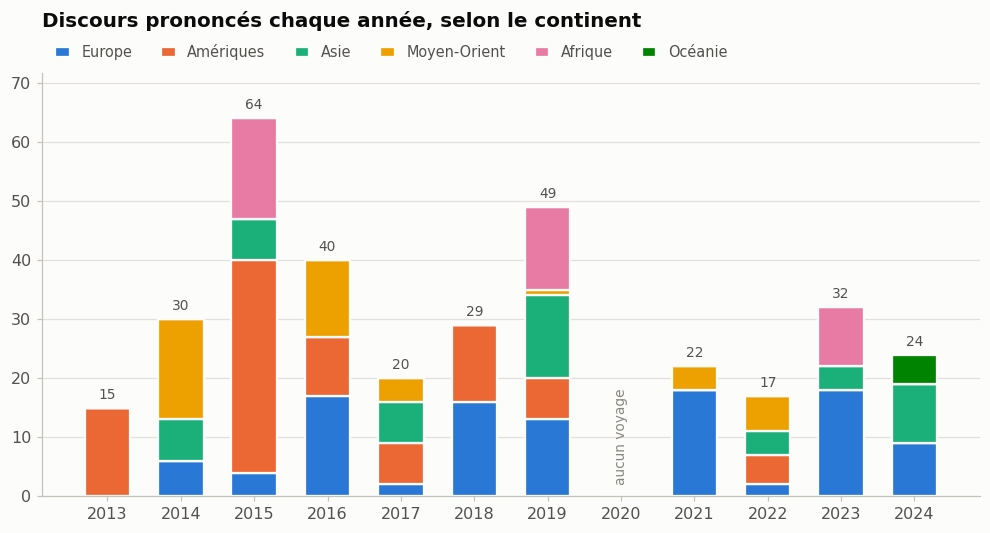

In [5]:
par_annee = (df.groupby(["annee", "continent"]).size().unstack(fill_value=0)
               .reindex(index=range(2013, 2025), columns=ac.ORDRE_CONTINENTS, fill_value=0))

fig, ax = plt.subplots(figsize=(11, 5))
bas = np.zeros(len(par_annee))
for continent in par_annee.columns:
    ax.bar(par_annee.index, par_annee[continent], bottom=bas, width=0.62, label=continent,
           color=g.COULEUR_CONTINENT[continent], edgecolor=g.FOND, linewidth=1.5)
    bas += par_annee[continent].to_numpy()

for annee, total in par_annee.sum(axis=1).items():
    if total > 0:
        ax.text(annee, total + 1, total, ha="center", va="bottom", fontsize=9, color=g.ENCRE_2)
ax.text(2020, 2, "aucun voyage", ha="center", va="bottom", fontsize=9, color=g.GRIS, rotation=90)

ax.set_xticks(par_annee.index)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, par_annee.sum(axis=1).max() * 1.12)
ax.legend(ncols=6, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1, fontsize=9.5)
ax.set_title("Discours prononcés chaque année, selon le continent", pad=30)
plt.show()

> À rédiger. Comment le rythme des voyages évolue-t-il ? Que se passe-t-il en 2020 et après ? Les continents se succèdent-ils ou se mélangent-ils ?

### À qui parle-t-il ?

Le type de public est déduit du titre. Par exemple « Meeting with the Authorities, Civil Society and the Diplomatic Corps » est classé dans « Autorités et diplomatie ».

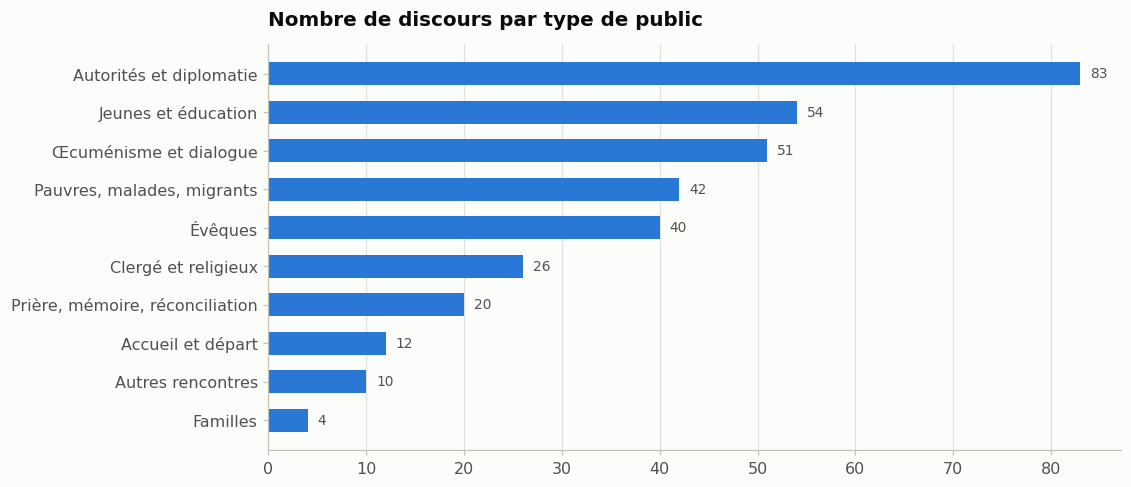

In [6]:
publics = df["public"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(publics.index, publics.values, height=0.6, color=g.COULEURS[0])
for i, n in enumerate(publics.values):
    ax.text(n + 1, i, n, va="center", fontsize=9, color=g.ENCRE_2)
ax.grid(axis="y", visible=False)
g.titre(ax, "Nombre de discours par type de public")
plt.show()

> À rédiger. Quels publics dominent ? Qu'est-ce que cela dit de la nature de ces voyages ?

### Combien de temps parle-t-il ?

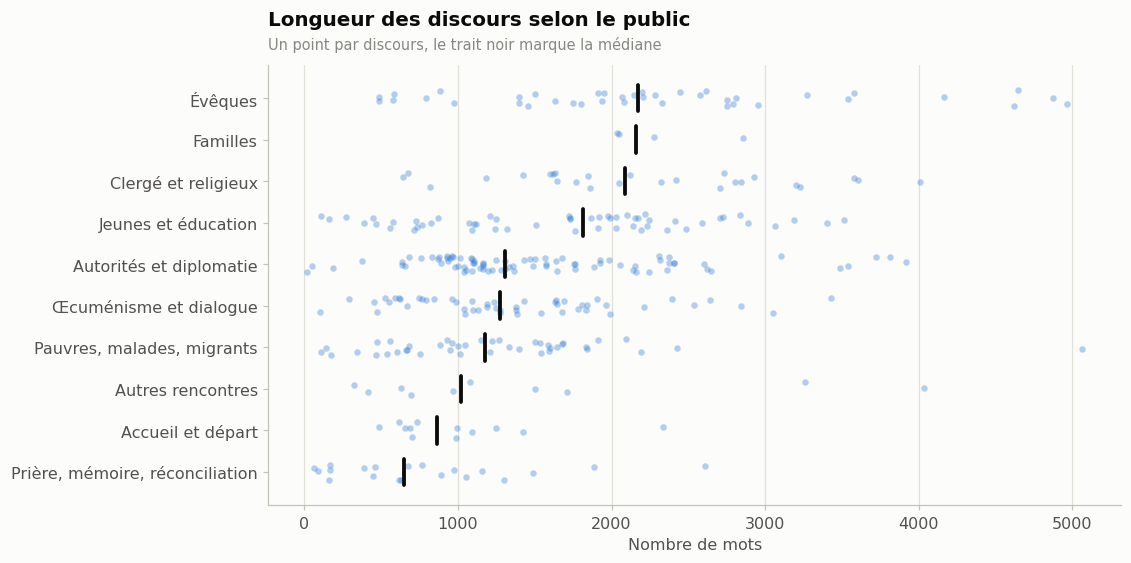

In [7]:
ordre = df.groupby("public")["n_mots"].median().sort_values().index
hasard = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(10, 5.2))
for i, public in enumerate(ordre):
    longueurs = df.loc[df["public"] == public, "n_mots"]
    decalage = hasard.uniform(-0.2, 0.2, len(longueurs))
    ax.scatter(longueurs, i + decalage, s=18, color=g.COULEURS[0], alpha=0.35, linewidths=0)
    ax.plot([longueurs.median()] * 2, [i - 0.32, i + 0.32], color=g.ENCRE, linewidth=2.5)
ax.set_yticks(range(len(ordre)), ordre)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Nombre de mots")
g.titre(ax, "Longueur des discours selon le public", "Un point par discours, le trait noir marque la médiane")
plt.show()

> À rédiger. Quels discours sont les plus longs, lesquels les plus courts ? Est-ce attendu ?

## 3. Le discours change-t-il selon le pays et le public ?

On mesure l'adaptation de trois façons : la mention du pays hôte, les thèmes abordés et les mots propres à chaque continent. On termine par l'évolution dans le temps. L'Océanie, qui ne compte que 5 discours, est laissée de côté dans les comparaisons par continent, comme les publics de moins de 10 discours.

### Parle-t-il du pays où il se trouve ?

On regarde si le texte nomme le pays où le discours est prononcé, par exemple « Kenya » dans un discours à Nairobi.

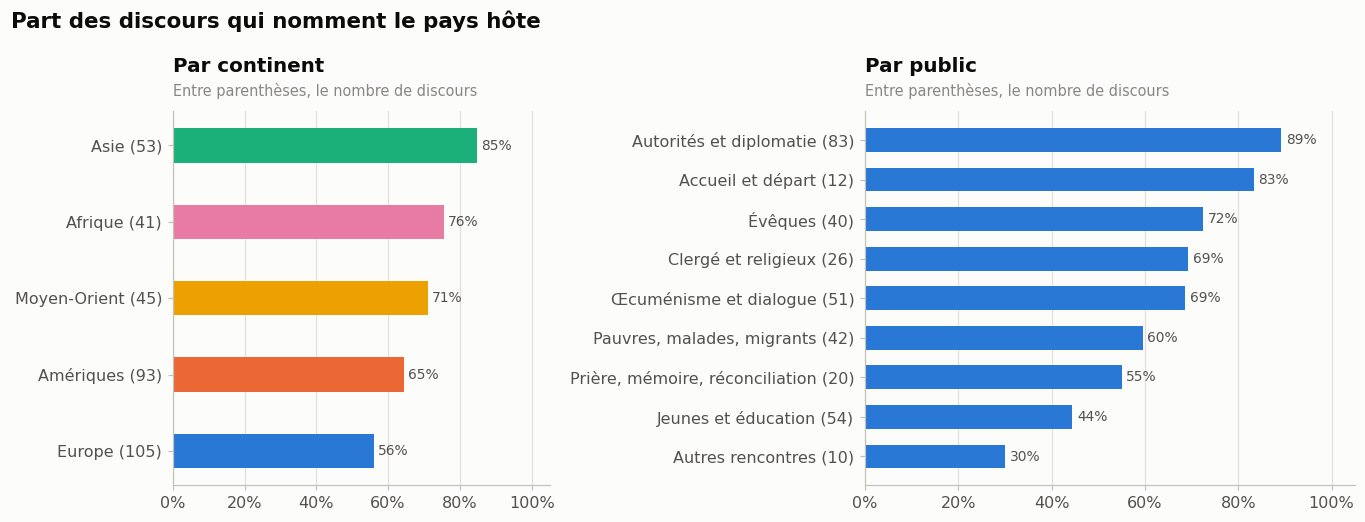

In [8]:
df["cite_hote"] = ac.cite_le_pays_hote(df)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
for ax, groupe in zip(axes, ["continent", "public"]):
    parts = df.groupby(groupe)["cite_hote"].agg(["mean", "size"])
    parts = parts[parts["size"] >= 10].sort_values("mean")
    couleurs = [g.COULEUR_CONTINENT.get(nom, g.COULEURS[0]) for nom in parts.index]
    etiquettes = [f"{nom} ({n})" for nom, n in zip(parts.index, parts["size"])]
    ax.barh(etiquettes, parts["mean"], height=0.45 if groupe == "continent" else 0.6, color=couleurs)
    for i, part in enumerate(parts["mean"]):
        ax.text(part + 0.01, i, f"{part:.0%}", va="center", fontsize=9, color=g.ENCRE_2)
    ax.set_xlim(0, 1.05)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", visible=False)
    g.titre(ax, f"Par {groupe}", "Entre parenthèses, le nombre de discours")
fig.suptitle("Part des discours qui nomment le pays hôte", x=0.01, ha="left",
             fontsize=14, fontweight="semibold", color=g.ENCRE)
fig.tight_layout()
plt.show()

> À rédiger. Le pays hôte est-il presque toujours nommé ? Pour quels continents et quels publics l'est-il moins ? Comment l'expliquer ?

### De quoi parle-t-il selon le continent ?

On définit 15 thèmes par des listes de mots anglais. Par exemple, le thème « Paix et guerre » regroupe « peace », « war », « weapons », « conflict »... Pour chaque continent, on compte les mentions de chaque thème pour 10 000 mots. La mesure est simple et vérifiable, mais elle compte des mots et non des idées.

La couleur se lit ligne par ligne : la case la plus foncée indique le continent où le thème revient le plus, la plus claire celui où il revient le moins. Les listes de mots sont dans `outils/analyse_corpus.py`.

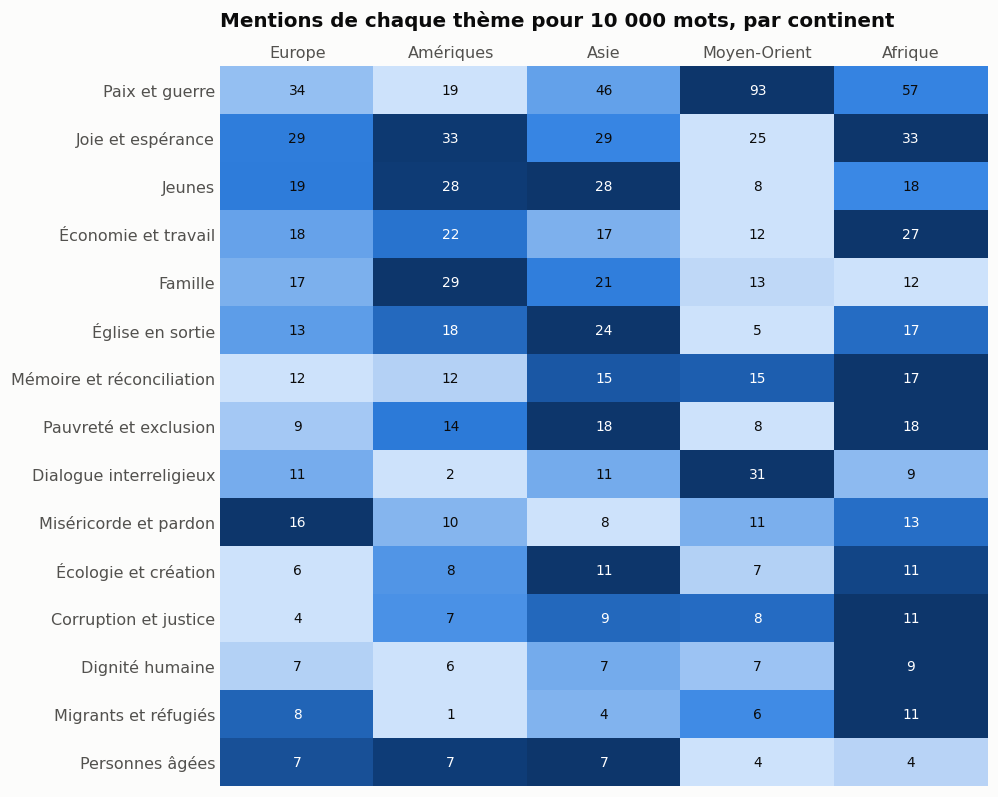

In [9]:
grands_continents = [c for c in ac.ORDRE_CONTINENTS if (df["continent"] == c).sum() >= 10]
taux = ac.taux_lexique(df, "continent").loc[grands_continents].T
taux = taux.loc[taux.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 8.5))
relatif = taux.sub(taux.min(axis=1), axis=0).div(taux.max(axis=1) - taux.min(axis=1), axis=0)
g.carte_chaleur(ax, taux, couleurs=relatif)
g.titre(ax, "Mentions de chaque thème pour 10 000 mots, par continent")
ax.title.set_position((0, 1.04))
plt.show()

> À rédiger. Quels thèmes varient le plus d'un continent à l'autre ? Lesquels restent stables partout ? Les écarts correspondent-ils à ce qu'on sait des pays visités ?

### Et selon le public ?

Même mesure, en comparant les types de public qui comptent au moins 20 discours.

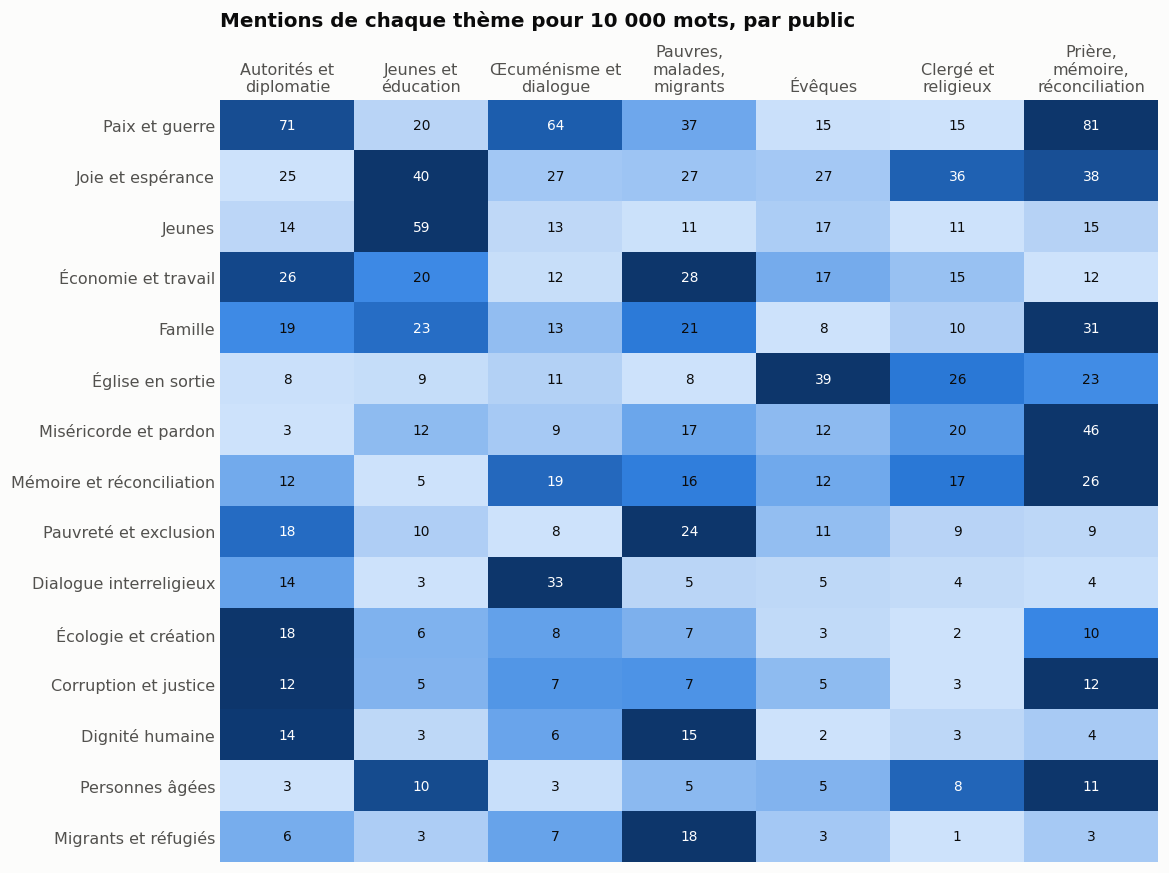

In [10]:
grands_publics = df["public"].value_counts().loc[lambda n: n >= 20].index
taux = ac.taux_lexique(df, "public").loc[grands_publics].T
taux = taux.loc[taux.mean(axis=1).sort_values(ascending=False).index]
taux.columns = [textwrap.fill(p, 14) for p in taux.columns]

fig, ax = plt.subplots(figsize=(11, 9))
relatif = taux.sub(taux.min(axis=1), axis=0).div(taux.max(axis=1) - taux.min(axis=1), axis=0)
g.carte_chaleur(ax, taux, couleurs=relatif)
g.titre(ax, "Mentions de chaque thème pour 10 000 mots, par public")
ax.title.set_position((0, 1.08))
plt.show()

> À rédiger. Le vocabulaire change-t-il plus selon le public ou selon le continent ? Quels thèmes sont réservés à un public précis ?

### Les mots propres à chaque continent

Pour chaque continent, on cherche les mots plus fréquents que dans le reste du corpus. Le score utilisé, le log-odds avec a priori de Dirichlet (Monroe, Colaresi et Quinn, 2008), tient compte de la taille de chaque groupe et limite le poids des mots rares. Au-dessus de 2, l'écart est net. Les noms de lieux ressortent logiquement en tête.

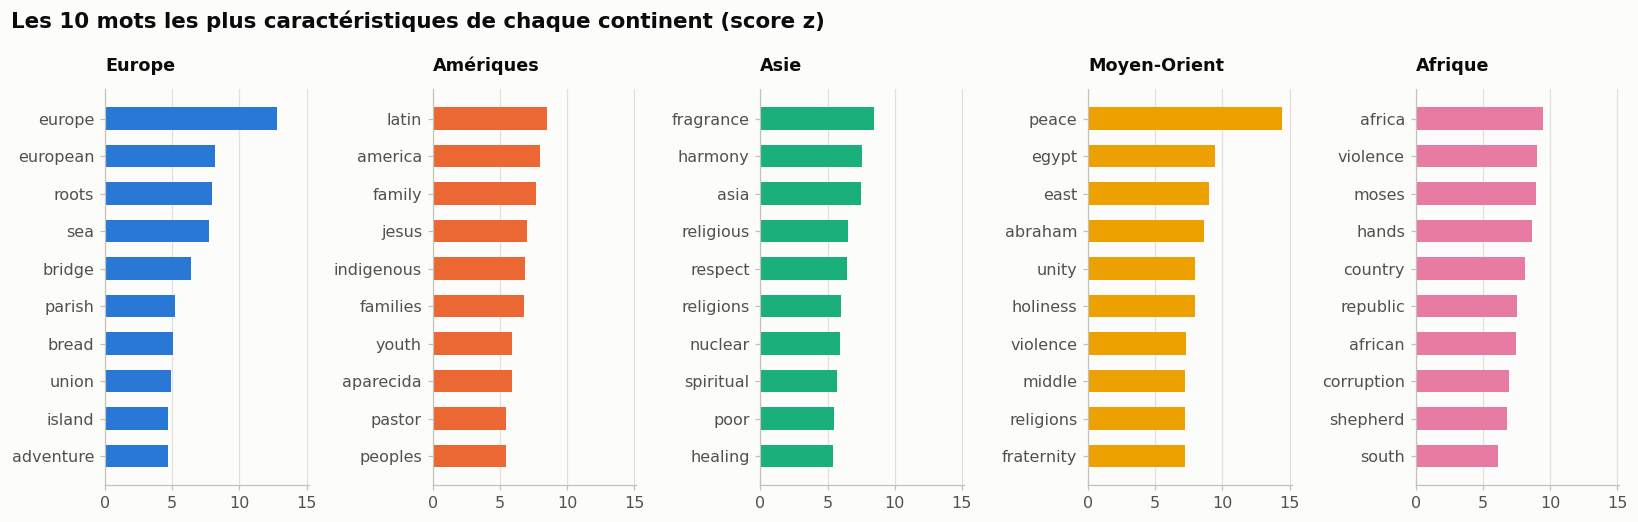

In [11]:
mots_par_continent = ac.mots_caracteristiques(df, "continent", n=10)
continents = [c for c in ac.ORDRE_CONTINENTS if c in mots_par_continent]

fig, axes = plt.subplots(1, len(continents), figsize=(15, 4.8), sharex=True)
for ax, continent in zip(axes, continents):
    scores = mots_par_continent[continent].iloc[::-1]
    ax.barh(scores.index, scores.values, height=0.6, color=g.COULEUR_CONTINENT[continent])
    ax.set_title(continent, fontsize=11.5)
    ax.grid(axis="y", visible=False)
fig.suptitle("Les 10 mots les plus caractéristiques de chaque continent (score z)", x=0.01, ha="left",
             fontsize=14, fontweight="semibold", color=g.ENCRE)
fig.tight_layout()
plt.show()

> À rédiger. Au-delà des noms de lieux, quels mots ressortent ? Que disent-ils des sujets propres à chaque région ?

### Le discours évolue-t-il dans le temps ?

On suit quatre thèmes année par année. Le trait gris donne la moyenne sur tous les voyages. Certaines années ne comptent qu'un ou deux voyages, les variations y sont donc fragiles.

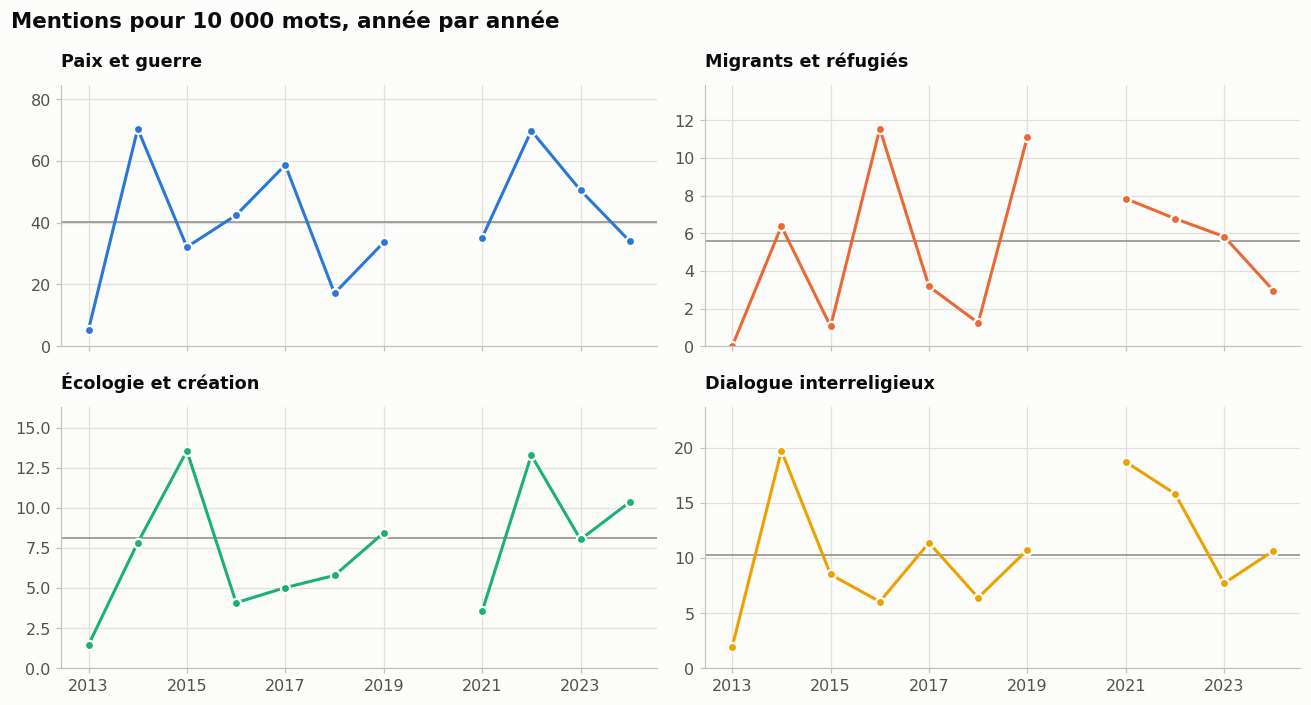

In [12]:
themes = ["Paix et guerre", "Migrants et réfugiés", "Écologie et création", "Dialogue interreligieux"]
par_annee = ac.taux_lexique(df, "annee").reindex(range(2013, 2025))
moyenne = ac.taux_lexique(df.assign(tous="ensemble"), "tous").loc["ensemble"]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, theme, couleur in zip(axes.flat, themes, g.COULEURS):
    ax.axhline(moyenne[theme], color=g.GRIS, linewidth=1)
    ax.plot(par_annee.index, par_annee[theme], color=couleur, marker="o", markersize=6,
            markeredgecolor=g.FOND, markeredgewidth=1.5)
    ax.set_ylim(0, par_annee[theme].max() * 1.2)
    ax.set_title(theme, fontsize=11.5)
    ax.set_xticks(range(2013, 2025, 2))
fig.suptitle("Mentions pour 10 000 mots, année par année", x=0.01, ha="left",
             fontsize=14, fontweight="semibold", color=g.ENCRE)
fig.tight_layout()
plt.show()

> À rédiger. Certains thèmes prennent-ils de l'importance ou en perdent-ils ? Les pics correspondent-ils à des voyages précis ?

## 4. Limites

- Les textes analysés sont les versions anglaises publiées par le Vatican. Une grande partie des discours a été prononcée en espagnol ou en italien, on travaille donc souvent sur une traduction.
- Le pays et le public sont déduits automatiquement de l'en-tête et du titre. Quelques erreurs restent possibles, par exemple « Georgia » peut désigner l'État américain.
- Les thèmes reposent sur des listes de mots choisies par nous. Un mot peut avoir un autre sens, et une idée peut s'exprimer sans ces mots.
- Les groupes sont de tailles inégales. L'Océanie compte 5 discours et certaines années un seul voyage. Les écarts entre petits groupes sont à lire avec prudence.

> À rédiger. Complétez avec vos propres remarques sur les données et la méthode.

## 5. Conclusion

> À rédiger. La réponse à la question de départ, en vous appuyant sur les graphiques ci-dessus. Le pape adapte-t-il son discours, et sur quels points ?